In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

C:\Users\sudee\AppData\Roaming\Python\Python39\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\sudee\AppData\Roaming\Python\Python39\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# Load data
df=pd.read_csv("Nat_Gas.csv")
df.head()

,Dates,Prices
0,10/31/20,10.1
1,11/30/20,10.3
2,12/31/20,11.0
3,1/31/21,10.9
4,2/28/21,10.9


In [3]:
df["Dates"]=pd.to_datetime(df["Dates"])
df = df.sort_values("Dates").reset_index(drop=True)

C:\Users\sudee\AppData\Local\Temp\ipykernel_19620\2546988450.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Dates"]=pd.to_datetime(df["Dates"])


In [4]:
df.head()

,Dates,Prices
0,2020-10-31,10.1
1,2020-11-30,10.3
2,2020-12-31,11.0
3,2021-01-31,10.9
4,2021-02-28,10.9


In [5]:
# Create time index
df["t"] = np.arange(len(df))
df.head()

,Dates,Prices,t
0,2020-10-31,10.1,0
1,2020-11-30,10.3,1
2,2020-12-31,11.0,2
3,2021-01-31,10.9,3
4,2021-02-28,10.9,4


In [6]:
# Trend Estimation
# Linear trend
trend = np.polyfit(df["t"], df["Prices"], 1)

In [7]:
# Monthly seasonal component
df["Month"] = df["Dates"].dt.month
monthly_avg = df.groupby("Month")["Prices"].mean()
monthly_avg

Month
1     11.775
2     11.700
3     11.775
4     11.175
5     10.785
6     10.700
7     10.900
8     10.825
9     11.075
10    10.750
11    11.325
12    11.700
Name: Prices, dtype: float64

In [8]:
# Forecast Next 12 Months

In [9]:
future_dates = pd.date_range(
    start=df["Dates"].iloc[-1] + pd.offsets.MonthEnd(),
    periods=12,
    freq="ME"
)

future_t = np.arange(len(df), len(df) + 12)

future_prices = []

for t, date in zip(future_t, future_dates):
    trend_price = trend[0] * t + trend[1]

    seasonal_adjustment = (
        monthly_avg[date.month] - monthly_avg.mean()
    )

    future_prices.append(trend_price + seasonal_adjustment)

future_df = pd.DataFrame({
    "Dates": future_dates,
    "Prices": future_prices
})

In [10]:
future_df

,Dates,Prices
0,2024-10-31,11.705824
1,2024-11-30,12.319838
2,2024-12-31,12.733851
3,2025-01-31,12.847864
4,2025-02-28,12.811877
5,2025-03-31,12.925891
6,2025-04-30,12.364904
7,2025-05-31,12.013917
8,2025-06-30,11.967930
9,2025-07-31,12.206944


In [11]:
# Combine historical + forecast
all_data = pd.concat([df[["Dates", "Prices"]], future_df], ignore_index=True)

In [12]:
all_data

,Dates,Prices
0,2020-10-31,10.100000
1,2020-11-30,10.300000
2,2020-12-31,11.000000
3,2021-01-31,10.900000
4,2021-02-28,10.900000
5,2021-03-31,10.900000
6,2021-04-30,10.400000
7,2021-05-31,9.840000
8,2021-06-30,10.000000
9,2021-07-31,10.100000


In [13]:
# Price Estimation Function

In [14]:
# Convert dates into numeric values
x = all_data["Dates"].map(pd.Timestamp.toordinal)
y = all_data["Prices"]

interpolator = interp1d(
    x,
    y,
    kind="linear",
    fill_value="extrapolate"
)

def estimate_price(date):

    date = pd.to_datetime(date)
    return float(interpolator(date.toordinal()))

In [38]:
print("Estimated Price:", estimate_price("2025-03-15"))

Estimated Price: 12.867045140980204


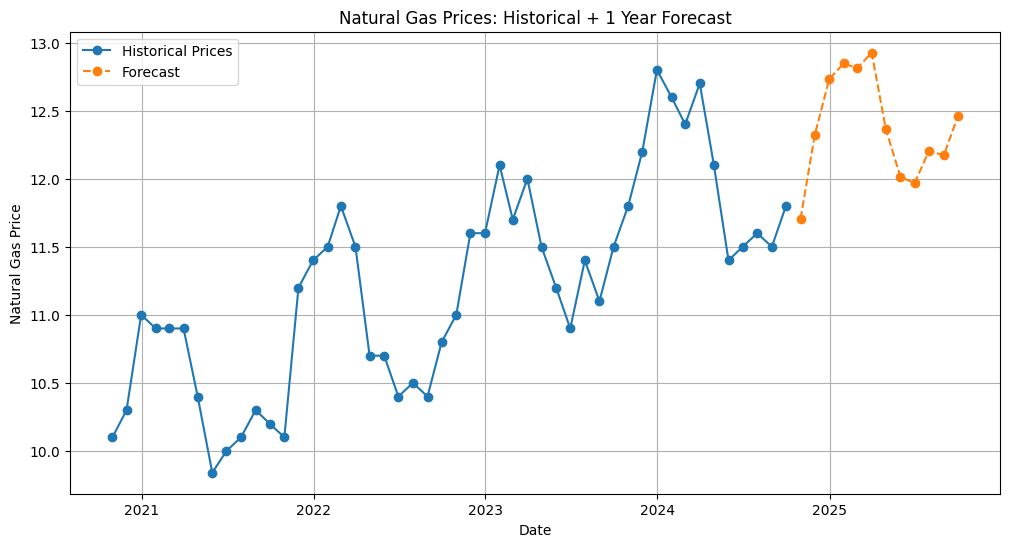

In [41]:
# Visualization
plt.figure(figsize=(12,6))

plt.plot(df["Dates"], df["Prices"],
         marker="o",
         label="Historical Prices")

plt.plot(future_df["Dates"], future_df["Prices"],
         marker="o",
         linestyle="--",
         label="Forecast")

plt.xlabel("Date")
plt.ylabel("Natural Gas Price")
plt.title("Natural Gas Prices: Historical + 1 Year Forecast")
plt.legend()
plt.grid(True)

plt.show()